# SECOM failure detection — v3: best-model search

**Goal.** Find the best failure detector for the SECOM semiconductor dataset (1567 wafers, 590 sensors, 104 fails = 6.6%), building on the v2 notebook (`SECOM_LR_vs_RF_v2.ipynb`).

**What v2 taught us** (cost = 10·missed fail + 1·false alarm, per wafer; majority baseline 0.664):
quantile-transformed logistic regression (LR) beats standardised LR; a random forest (RF) ranks better than LR (ROC-AUC 0.74 vs 0.69); top-k sensor selection, naive detrending and an untuned gradient-boosting model did not help; best v2 result was the average of an L1-LR and a tuned RF (cost 0.490, PR-AUC ≈ 0.22); late wafers are much harder (drift).

**What is new here.**
1. Evaluation built to avoid the leakage common in published SECOM results: *every* imputer, selector, resampler, tuner and threshold lives inside the training fold.
2. PR-AUC as the primary ranking metric (6.6% positives), plus ROC-AUC, recall in the top 10% of flagged wafers, MCC and expected cost.
3. A wider model search (ExtraTrees, balanced forests, LightGBM, SMOTE variants, rank-based feature selection, missingness features).
4. Nested Optuna tuning for the shortlist, calibrated members, an ensemble, and a cost-optimal threshold chosen on *inner* out-of-fold predictions only.
5. A chronological hold-out (train on the first 75% of wafers, test on the last 25%) as an honesty check against drift.

**How to run.** Needs `secom.data` and `secom_labels.data` in the working directory. Results are cached in `cache_v3/`. Set env `SECOM_FAST=1` for a quick smoke test.

## 0. Setup

In [1]:
import os, re, time, pickle, warnings
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from joblib import Parallel, delayed
import optuna
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score, average_precision_score, matthews_corrcoef
from lightgbm import LGBMClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

FAST = os.environ.get("SECOM_FAST") == "1"
SEED = 42
N_SPLITS, N_REPEATS = 5, (1 if FAST else 5)       # screening CV: 5x5 = 25 held-out folds (same seed as v2)
TUNE_REPEATS = 1 if FAST else 2                    # nested-tuning CV: 5x2 = 10 outer folds
N_TRIALS = 3 if FAST else 20                       # Optuna trials per member per outer fold
N_JOBS = min(8, os.cpu_count() or 1)
COST_FN, COST_FP = 10, 1                           # same cost rule as v2
DATA_DIR = Path(".")
CACHE = Path("cache_v3"); CACHE.mkdir(exist_ok=True)
RESULTS = Path("results_v3"); RESULTS.mkdir(exist_ok=True)
TAG = "_fast" if FAST else ""
print(f"sklearn {sklearn.__version__} | FAST={FAST} | jobs={N_JOBS} | repeats={N_REPEATS} | tune folds={N_SPLITS*TUNE_REPEATS} | trials={N_TRIALS}")

sklearn 1.6.1 | FAST=False | jobs=8 | repeats=5 | tune folds=10 | trials=20


## 1. Data and EDA
Each EDA step ends with the preprocessing decision it justifies.

In [2]:
X_raw = pd.read_csv(DATA_DIR / "secom.data", sep=r"\s+", header=None)
lab = pd.read_csv(DATA_DIR / "secom_labels.data", sep=r"\s+", header=None, names=["label", "timestamp"])
lab["timestamp"] = pd.to_datetime(lab["timestamp"].str.strip('"'), format="%d/%m/%Y %H:%M:%S")
order = np.argsort(lab["timestamp"].values, kind="stable")
print("timestamps already chronological:", bool((order == np.arange(len(order))).all()))
X_raw = X_raw.iloc[order].reset_index(drop=True)
lab = lab.iloc[order].reset_index(drop=True)
X = X_raw.values.astype(float)
y = (lab["label"].values == 1).astype(int)
t = lab["timestamp"]
print(f"wafers={len(y)}, sensors={X.shape[1]}, fails={y.sum()} ({y.mean():.1%}), span {t.min().date()} → {t.max().date()}")

timestamps already chronological: True
wafers=1567, sensors=590, fails=104 (6.6%), span 2008-07-19 → 2008-10-17


sensors with >50% missing: 28 | >0% missing: 538 | constant (≤1 unique): 116


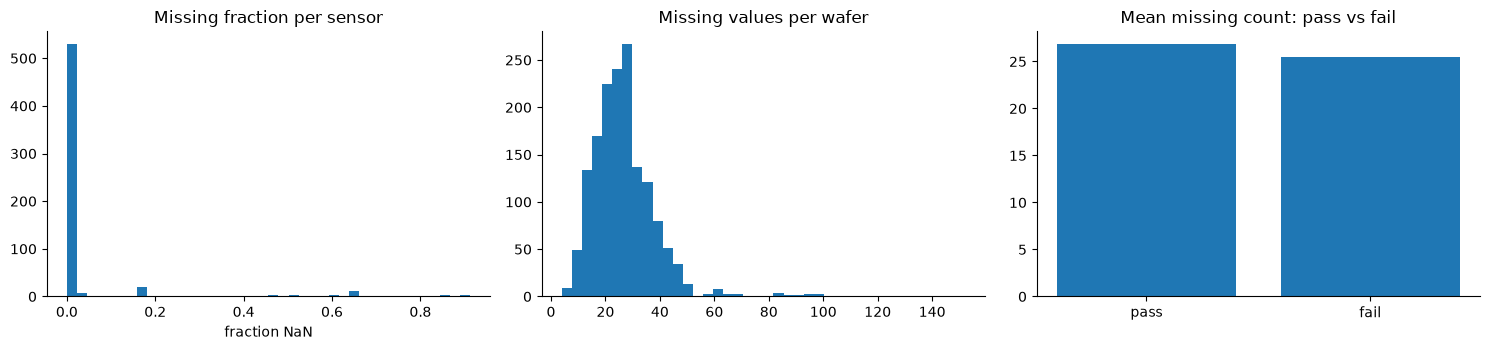

Mean NaN count — pass: 26.9, fail: 25.5; AUC of NaN-count alone: 0.473


In [3]:
miss = np.isnan(X).mean(0)
nun = np.array([len(np.unique(X[~np.isnan(X[:, j]), j])) for j in range(X.shape[1])])
print(f"sensors with >50% missing: {(miss > .5).sum()} | >0% missing: {(miss > 0).sum()} | constant (≤1 unique): {(nun <= 1).sum()}")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(miss, bins=40); ax[0].set_title("Missing fraction per sensor"); ax[0].set_xlabel("fraction NaN")
nan_count = np.isnan(X).sum(1)
ax[1].hist(nan_count, bins=40); ax[1].set_title("Missing values per wafer")
ax[2].bar(["pass", "fail"], [nan_count[y == 0].mean(), nan_count[y == 1].mean()]); ax[2].set_title("Mean missing count: pass vs fail")
plt.tight_layout(); plt.show()
print("Mean NaN count — pass: %.1f, fail: %.1f; AUC of NaN-count alone: %.3f" % (nan_count[y == 0].mean(), nan_count[y == 1].mean(), roc_auc_score(y, nan_count)))
# Decision: drop sensors that are constant or >50% missing (fit on training fold); median-impute the rest;
# add the per-wafer missing count as a feature only if it carries signal (checked as an ablation below).

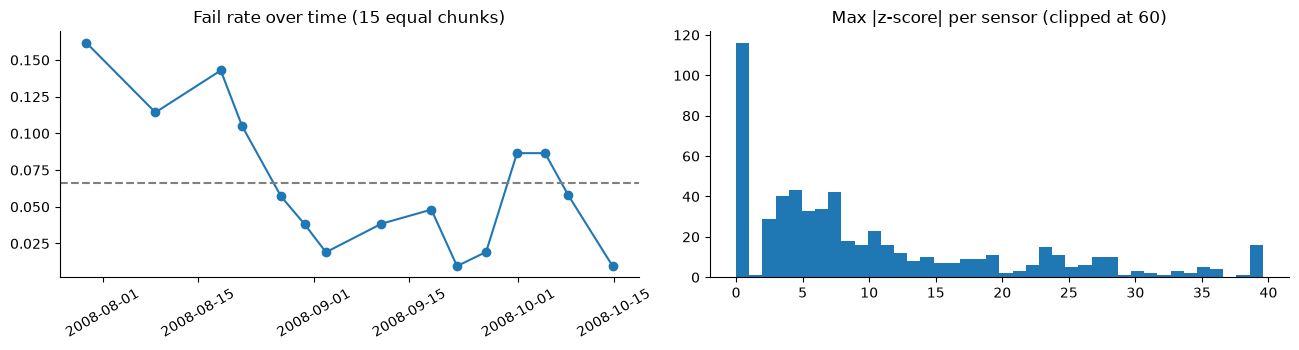

sensors with a reading >10 SD from their mean: 217


In [4]:
# Fail rate over time (drift) and sensor outliers
bins = np.array_split(np.arange(len(y)), 15)
rates = [y[b].mean() for b in bins]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot([t.iloc[b].mean() for b in bins], rates, "o-"); ax[0].axhline(y.mean(), ls="--", c="grey")
ax[0].set_title("Fail rate over time (15 equal chunks)"); ax[0].tick_params(axis="x", rotation=30)
Z = (X - np.nanmean(X, 0)) / (np.nanstd(X, 0) + 1e-12)
mx = np.nanmax(np.abs(Z), 0)
ax[1].hist(np.clip(mx[np.isfinite(mx)], 0, 60), bins=40); ax[1].set_title("Max |z-score| per sensor (clipped at 60)")
plt.tight_layout(); plt.show()
print("sensors with a reading >10 SD from their mean:", int((mx > 10).sum()))
# Decision: heavy outliers → quantile/rank-based transforms for linear models and rank-based feature selection; trees are robust.
# Fail rate varies over time → the chronological hold-out is a necessary honesty check.

sensors with univariate AUC > 0.60: 21 | > 0.65: 7 | max: 0.692


max univariate AUC under shuffled labels (noise level): 0.629


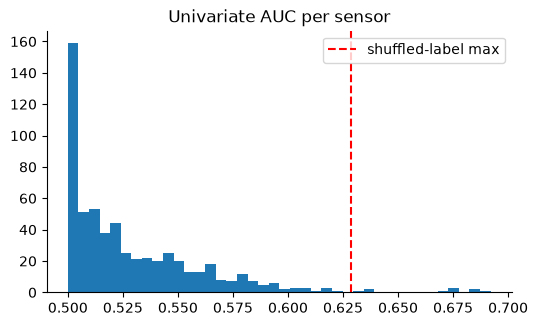

In [5]:
# Univariate signal: direction-free AUC per sensor (computed on all data purely for EDA; selection inside CV is redone per fold)
def uni_auc(Xc, yc):
    out = np.full(Xc.shape[1], 0.5)
    for j in range(Xc.shape[1]):
        ok = ~np.isnan(Xc[:, j])
        if ok.sum() > 50 and yc[ok].sum() >= 5 and np.unique(Xc[ok, j]).size > 1:
            a = roc_auc_score(yc[ok], Xc[ok, j]); out[j] = max(a, 1 - a)
    return out
ua = uni_auc(X, y)
print("sensors with univariate AUC > 0.60: %d | > 0.65: %d | max: %.3f" % ((ua > .6).sum(), (ua > .65).sum(), ua.max()))
rng = np.random.RandomState(0)
perm_max = np.max([uni_auc(X, rng.permutation(y)).max() for _ in range(3)])
print("max univariate AUC under shuffled labels (noise level): %.3f" % perm_max)
plt.figure(figsize=(6, 3.4)); plt.hist(ua, bins=40); plt.axvline(perm_max, c="r", ls="--", label="shuffled-label max"); plt.legend(); plt.title("Univariate AUC per sensor"); plt.show()
# Decision: only a few dozen sensors carry signal above the noise level → feature selection is a legitimate candidate,
# but must be evaluated inside folds (v2 found simple top-k did not help, so it is tested together with other choices).

In [6]:
# Redundancy: groups of near-copies
Xi = np.where(np.isnan(X), np.nanmedian(X, 0), X)
keep0 = (nun > 1) & (miss <= .5)
C = np.abs(np.corrcoef(rankdata(Xi[:, keep0], axis=0).T))
print("sensor pairs with |rank corr| > 0.95:", int((np.triu(C, 1) > .95).sum()), "among", int(keep0.sum()), "usable sensors")
# Decision: strong redundancy → L1 / tree-based models and a correlation filter are reasonable; an extra step is tested as ablation.

sensor pairs with |rank corr| > 0.95: 223 among 446 usable sensors


## 2. Evaluation harness
Repeated stratified 5×5 CV (same seed as v2). All fitting happens in `fit_predict` on the training rows only.

In [7]:
class Cleaner(BaseEstimator, TransformerMixin):
    """Drops constant sensors and sensors with too many NaNs (decided on training rows); optional per-wafer NaN count."""
    def __init__(self, max_missing=0.5, add_nan_count=False):
        self.max_missing, self.add_nan_count = max_missing, add_nan_count
    def fit(self, X, y=None):
        X = np.asarray(X, float)
        nanf = np.isnan(X).mean(0)
        const = np.array([np.unique(X[~np.isnan(X[:, j]), j]).size <= 1 for j in range(X.shape[1])])
        self.keep_ = np.where((nanf <= self.max_missing) & ~const)[0]
        return self
    def transform(self, X):
        X = np.asarray(X, float)
        out = X[:, self.keep_]
        if self.add_nan_count:
            out = np.column_stack([out, np.isnan(X).sum(1)])
        return out

class RankSelector(BaseEstimator, TransformerMixin):
    """Keeps the k sensors with the largest |mean rank difference| between fails and passes (robust to outliers)."""
    def __init__(self, k=60):
        self.k = k
    def fit(self, X, y):
        R = rankdata(X, axis=0) / len(X)
        d = np.abs(R[y == 1].mean(0) - R[y == 0].mean(0))
        self.idx_ = np.argsort(-d)[: self.k]
        return self
    def transform(self, X):
        return X[:, self.idx_]

class CorrFilter(BaseEstimator, TransformerMixin):
    """Greedily drops sensors whose |rank correlation| with an already kept sensor exceeds a threshold."""
    def __init__(self, thr=0.95):
        self.thr = thr
    def fit(self, X, y=None):
        C = np.abs(np.corrcoef(rankdata(X, axis=0).T)); C = np.nan_to_num(C)
        keep = []
        for j in range(X.shape[1]):
            if all(C[j, k] <= self.thr for k in keep):
                keep.append(j)
        self.idx_ = np.array(keep)
        return self
    def transform(self, X):
        return X[:, self.idx_]

def cv_splits(n_repeats):
    return list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=n_repeats, random_state=SEED).split(X, y))
SPLITS = cv_splits(N_REPEATS)
TUNE_SPLITS = SPLITS[: N_SPLITS * TUNE_REPEATS]       # first repeats of the same splits

def _fit_predict(make, Xtr, ytr, Xte):
    m = make().fit(Xtr, ytr)
    return m.predict_proba(Xte)[:, 1]

def run_cv(name, make, splits=None, force=False):
    splits = SPLITS if splits is None else splits
    path = CACHE / f"cv_{re.sub(r'[^A-Za-z0-9_.-]', '_', name)}{TAG}.pkl"
    if path.exists() and not force:
        return pickle.load(open(path, "rb"))
    t0 = time.time()
    risks = Parallel(n_jobs=N_JOBS)(delayed(_fit_predict)(make, X[tr], y[tr], X[te]) for tr, te in splits)
    pickle.dump(risks, open(path, "wb"))
    print(f"  {name}: {time.time()-t0:.0f}s")
    return risks

def rank_metrics(yt, r):
    top = np.argsort(-r)[: int(np.ceil(0.10 * len(yt)))]
    return {"ROC-AUC": roc_auc_score(yt, r), "PR-AUC": average_precision_score(yt, r), "Recall@top10%": yt[top].sum() / yt.sum()}

def decision_metrics(yt, r, thr):
    f = (r >= thr).astype(int)
    fn = int(((f == 0) & (yt == 1)).sum()); fp = int(((f == 1) & (yt == 0)).sum()); tp = int(((f == 1) & (yt == 1)).sum())
    return {"Cost": (COST_FN * fn + COST_FP * fp) / len(yt), "Recall": tp / max(yt.sum(), 1), "Precision": tp / max(f.sum(), 1),
            "Flag rate": f.mean(), "MCC": matthews_corrcoef(yt, f) if f.sum() and f.sum() < len(f) else 0.0}

def fold_table(risks, splits=None):
    splits = SPLITS if splits is None else splits
    return pd.DataFrame([rank_metrics(y[te], r) for (tr, te), r in zip(splits, risks)])

def paired(a, b, splits=None, metric="PR-AUC"):
    """Nadeau–Bengio corrected paired t between two per-fold metric vectors (a − b)."""
    splits = SPLITS if splits is None else splits
    d = np.asarray(a[metric]) - np.asarray(b[metric]); k = len(d)
    ntr, nte = len(splits[0][0]), len(splits[0][1])
    se = np.sqrt((1 / k + nte / ntr) * d.var(ddof=1))
    return d.mean(), d.mean() / se if se > 0 else np.nan

SCORE = {}     # name -> per-fold metric table (screening, 25 folds)
def evaluate(name, make, splits=None, force=False):
    risks = run_cv(name, make, splits, force)
    SCORE[name] = fold_table(risks, splits)
    return risks

def screening_table(names=None, ref="LR quantile (v2-like)"):
    rows = []
    for n in (names or SCORE):
        f = SCORE[n]; row = {"model": n, "folds": len(f)}
        for m in ["PR-AUC", "ROC-AUC", "Recall@top10%"]:
            row[m] = f"{f[m].mean():.3f} ± {f[m].std():.3f}"
        if ref in SCORE and n != ref and len(SCORE[ref]) == len(f):
            dm, tt = paired(f, SCORE[ref]); row["ΔPR-AUC vs ref"] = f"{dm:+.3f} (t={tt:.1f})"
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")

## 3. Stage 1 — baselines and model families (default-ish settings)
`LR quantile (v2-like)` and `RF (v2-like)` re-create the v2 reference models in this harness so improvements are measured against the same folds.

In [8]:
def pre_tree(**kw):   return [("clean", Cleaner(**kw)), ("imp", SimpleImputer(strategy="median"))]
def pre_linear(**kw): return pre_tree(**kw) + [("q", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=SEED))]

def lr_grid(penalty="l2"):
    solver = "liblinear" if penalty == "l1" else "lbfgs"
    return GridSearchCV(LogisticRegression(penalty=penalty, solver=solver, max_iter=2000), {"C": np.logspace(-4, 0, 5)},
                        scoring="neg_log_loss", cv=StratifiedKFold(3, shuffle=True, random_state=SEED))

print("Stage 1 (25 folds each)")
evaluate("LR quantile (v2-like)", lambda: Pipeline(pre_linear() + [("m", lr_grid("l2"))]))
evaluate("LR-L1 quantile",        lambda: Pipeline(pre_linear() + [("m", lr_grid("l1"))]))
evaluate("RF (v2-like)",          lambda: Pipeline(pre_tree() + [("m", RandomForestClassifier(500, min_samples_leaf=3, max_features="sqrt", n_jobs=1, random_state=SEED))]))
evaluate("RF balanced_subsample", lambda: Pipeline(pre_tree() + [("m", RandomForestClassifier(500, min_samples_leaf=3, max_features="sqrt", class_weight="balanced_subsample", n_jobs=1, random_state=SEED))]))
evaluate("ExtraTrees",            lambda: Pipeline(pre_tree() + [("m", ExtraTreesClassifier(500, min_samples_leaf=3, max_features="sqrt", class_weight="balanced_subsample", n_jobs=1, random_state=SEED))]))
evaluate("Balanced RF",           lambda: Pipeline(pre_tree() + [("m", BalancedRandomForestClassifier(300, min_samples_leaf=2, max_features="sqrt", sampling_strategy="all", replacement=True, n_jobs=1, random_state=SEED))]))
evaluate("LightGBM (regularised)", lambda: Pipeline([("clean", Cleaner()), ("m", LGBMClassifier(n_estimators=250, learning_rate=0.03, num_leaves=8, min_child_samples=15, subsample=0.7, subsample_freq=1,
                                                     colsample_bytree=0.3, reg_lambda=10, verbose=-1, n_jobs=1, random_state=SEED))]))
screening_table()

Stage 1 (25 folds each)


  LR quantile (v2-like): 11s


  LR-L1 quantile: 13s


  RF (v2-like): 63s


  RF balanced_subsample: 35s


  ExtraTrees: 11s


  Balanced RF: 8s


  LightGBM (regularised): 7s


,folds,PR-AUC,ROC-AUC,Recall@top10%,ΔPR-AUC vs ref
model,,,,,
LR quantile (v2-like),25,0.179 ± 0.043,0.706 ± 0.057,0.298 ± 0.082,NaN
LR-L1 quantile,25,0.209 ± 0.059,0.703 ± 0.056,0.289 ± 0.073,+0.031 (t=1.3)
RF (v2-like),25,0.204 ± 0.038,0.747 ± 0.052,0.329 ± 0.074,+0.025 (t=1.0)
RF balanced_subsample,25,0.208 ± 0.043,0.754 ± 0.039,0.307 ± 0.063,+0.029 (t=1.1)
ExtraTrees,25,0.192 ± 0.045,0.757 ± 0.045,0.288 ± 0.073,+0.013 (t=0.5)
Balanced RF,25,0.201 ± 0.041,0.749 ± 0.049,0.298 ± 0.073,+0.022 (t=0.9)
LightGBM (regularised),25,0.212 ± 0.050,0.737 ± 0.046,0.350 ± 0.083,+0.034 (t=1.3)


## 4. Stage 2 — preprocessing ablations
Missing-count feature, rank-based top-k selection, correlation filter, SMOTE. All are steps inside the pipeline, so selection and resampling only ever see training rows.

In [9]:
print("Stage 2 (25 folds each)")
ET = lambda: ExtraTreesClassifier(500, min_samples_leaf=3, max_features="sqrt", class_weight="balanced_subsample", n_jobs=1, random_state=SEED)
RF = lambda: RandomForestClassifier(500, min_samples_leaf=3, max_features="sqrt", n_jobs=1, random_state=SEED)
evaluate("ExtraTrees + NaN-count",   lambda: Pipeline(pre_tree(add_nan_count=True) + [("m", ET())]))
evaluate("ExtraTrees + top-30",      lambda: Pipeline(pre_tree() + [("sel", RankSelector(30)), ("m", ET())]))
evaluate("ExtraTrees + top-60",      lambda: Pipeline(pre_tree() + [("sel", RankSelector(60)), ("m", ET())]))
evaluate("ExtraTrees + top-120",     lambda: Pipeline(pre_tree() + [("sel", RankSelector(120)), ("m", ET())]))
evaluate("ExtraTrees + corr-filter", lambda: Pipeline(pre_tree() + [("cf", CorrFilter(0.95)), ("m", ET())]))
evaluate("RF + top-60",              lambda: Pipeline(pre_tree() + [("sel", RankSelector(60)), ("m", RF())]))
evaluate("RF + top-60 + SMOTE",      lambda: ImbPipeline(pre_tree() + [("sel", RankSelector(60)), ("smote", SMOTE(sampling_strategy=0.3, k_neighbors=5, random_state=SEED)), ("m", RF())]))
evaluate("LR-L1 + top-60",           lambda: Pipeline(pre_linear() + [("sel", RankSelector(60)), ("m", lr_grid("l1"))]))
evaluate("LightGBM + top-60",        lambda: Pipeline([("clean", Cleaner()), ("imp", SimpleImputer(strategy="median")), ("sel", RankSelector(60)),
                                                       ("m", LGBMClassifier(n_estimators=250, learning_rate=0.03, num_leaves=8, min_child_samples=15, subsample=0.7, subsample_freq=1,
                                                                            colsample_bytree=0.5, reg_lambda=10, verbose=-1, n_jobs=1, random_state=SEED))]))
tab = screening_table()
tab

Stage 2 (25 folds each)


  ExtraTrees + NaN-count: 10s


  ExtraTrees + top-30: 6s


  ExtraTrees + top-60: 6s


  ExtraTrees + top-120: 8s


  ExtraTrees + corr-filter: 10s


  RF + top-60: 18s


  RF + top-60 + SMOTE: 20s


  LR-L1 + top-60: 4s


  LightGBM + top-60: 2s


,folds,PR-AUC,ROC-AUC,Recall@top10%,ΔPR-AUC vs ref
model,,,,,
LR quantile (v2-like),25,0.179 ± 0.043,0.706 ± 0.057,0.298 ± 0.082,NaN
LR-L1 quantile,25,0.209 ± 0.059,0.703 ± 0.056,0.289 ± 0.073,+0.031 (t=1.3)
RF (v2-like),25,0.204 ± 0.038,0.747 ± 0.052,0.329 ± 0.074,+0.025 (t=1.0)
RF balanced_subsample,25,0.208 ± 0.043,0.754 ± 0.039,0.307 ± 0.063,+0.029 (t=1.1)
ExtraTrees,25,0.192 ± 0.045,0.757 ± 0.045,0.288 ± 0.073,+0.013 (t=0.5)
Balanced RF,25,0.201 ± 0.041,0.749 ± 0.049,0.298 ± 0.073,+0.022 (t=0.9)
LightGBM (regularised),25,0.212 ± 0.050,0.737 ± 0.046,0.350 ± 0.083,+0.034 (t=1.3)
ExtraTrees + NaN-count,25,0.199 ± 0.045,0.762 ± 0.042,0.317 ± 0.079,+0.020 (t=0.7)
ExtraTrees + top-30,25,0.188 ± 0.045,0.728 ± 0.051,0.294 ± 0.069,+0.009 (t=0.3)


**Reading the table.** ΔPR-AUC is paired against the v2-like LR on identical folds, with the Nadeau–Bengio correction for overlapping training sets (|t| ≳ 2 is a real difference; with only 104 failures, differences below ~0.02 PR-AUC are within noise).

In [10]:
best_by_pr = sorted(SCORE, key=lambda n: -SCORE[n]["PR-AUC"].mean())
print("Ranking by mean PR-AUC:"); [print(f"  {n:28s} PR {SCORE[n]['PR-AUC'].mean():.3f}  ROC {SCORE[n]['ROC-AUC'].mean():.3f}") for n in best_by_pr]

Ranking by mean PR-AUC:
  RF + top-60 + SMOTE          PR 0.219  ROC 0.736
  LightGBM (regularised)       PR 0.212  ROC 0.737
  LR-L1 quantile               PR 0.209  ROC 0.703
  RF + top-60                  PR 0.209  ROC 0.733
  RF balanced_subsample        PR 0.208  ROC 0.754
  LR-L1 + top-60               PR 0.208  ROC 0.727
  RF (v2-like)                 PR 0.204  ROC 0.747
  ExtraTrees + corr-filter     PR 0.203  ROC 0.762
  Balanced RF                  PR 0.201  ROC 0.749
  ExtraTrees + NaN-count       PR 0.199  ROC 0.762
  LightGBM + top-60            PR 0.199  ROC 0.739
  ExtraTrees + top-60          PR 0.195  ROC 0.746
  ExtraTrees                   PR 0.192  ROC 0.757
  ExtraTrees + top-120         PR 0.191  ROC 0.754
  ExtraTrees + top-30          PR 0.188  ROC 0.728
  LR quantile (v2-like)        PR 0.179  ROC 0.706


[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

## 5. Stage 3 — nested hyper-parameter tuning + calibrated ensemble
For each of the 10 outer folds (5×2), and for each family (L1-LR, RF, ExtraTrees, LightGBM):
1. Optuna searches hyper-parameters using only the **outer-training rows** (inner 3-fold CV, objective = PR-AUC).
2. The chosen configuration yields inner out-of-fold risks; a Platt scaler is fitted on them so members are comparable probabilities.
3. The member is refitted on the whole outer-training set and scored on the outer-test fold.
4. Ensembles average the calibrated members. The decision threshold minimises the 10:1 cost on the **inner out-of-fold** ensemble risks — the outer-test fold never influences it.

In [11]:
def make_est(kind, p, seed=SEED):
    if kind == "lr":
        return Pipeline(pre_linear() + [("sel", RankSelector(p["k"])), ("m", LogisticRegression(penalty="l1", solver="liblinear", C=p["C"], max_iter=2000))])
    if kind == "rf":
        return Pipeline(pre_tree() + [("sel", RankSelector(p["k"])), ("m", RandomForestClassifier(300, min_samples_leaf=p["leaf"], max_features=p["mf"],
                         class_weight=p["cw"], n_jobs=1, random_state=seed))])
    if kind == "et":
        return Pipeline(pre_tree() + [("sel", RankSelector(p["k"])), ("m", ExtraTreesClassifier(300, min_samples_leaf=p["leaf"], max_features=p["mf"],
                         class_weight=p["cw"], n_jobs=1, random_state=seed))])
    if kind == "lgbm":
        return Pipeline(pre_tree() + [("sel", RankSelector(p["k"])), ("m", LGBMClassifier(n_estimators=p["n"], learning_rate=p["lr"], num_leaves=p["leaves"],
                         min_child_samples=p["mcs"], subsample=p["ss"], subsample_freq=1, colsample_bytree=p["cs"], reg_lambda=p["l2"],
                         scale_pos_weight=p["spw"], verbose=-1, n_jobs=1, random_state=seed))])

def suggest(trial, kind):
    k = trial.suggest_categorical("k", [30, 60, 120, 250])
    if kind == "lr":   return {"k": k, "C": trial.suggest_float("C", 1e-3, 1.0, log=True)}
    if kind in ("rf", "et"):
        return {"k": k, "leaf": trial.suggest_int("leaf", 1, 10), "mf": trial.suggest_float("mf", 0.02, 0.4, log=True),
                "cw": trial.suggest_categorical("cw", [None, "balanced_subsample"])}
    return {"k": k, "n": trial.suggest_int("n", 100, 500, step=50), "lr": trial.suggest_float("lr", 0.01, 0.1, log=True),
            "leaves": trial.suggest_int("leaves", 3, 16), "mcs": trial.suggest_int("mcs", 5, 40), "ss": trial.suggest_float("ss", 0.5, 1.0),
            "cs": trial.suggest_float("cs", 0.1, 0.8), "l2": trial.suggest_float("l2", 0.1, 50, log=True), "spw": trial.suggest_float("spw", 1, 15)}

def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))[:, None]

def tune(kind, Xtr, ytr, seed):
    skf = StratifiedKFold(3, shuffle=True, random_state=seed)
    def obj(trial):
        p = suggest(trial, kind); trial.set_user_attr("p", p); sc = []
        for a, b in skf.split(Xtr, ytr):
            m = make_est(kind, p, seed).fit(Xtr[a], ytr[a]); sc.append(average_precision_score(ytr[b], m.predict_proba(Xtr[b])[:, 1]))
        return float(np.mean(sc))
    st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed)); st.optimize(obj, n_trials=N_TRIALS)
    return st.best_trial.user_attrs["p"], st.best_value

def member(kind, p, Xtr, ytr, Xte, seed):
    skf = StratifiedKFold(3, shuffle=True, random_state=seed + 1); oof = np.zeros(len(ytr))
    for a, b in skf.split(Xtr, ytr):
        oof[b] = make_est(kind, p, seed).fit(Xtr[a], ytr[a]).predict_proba(Xtr[b])[:, 1]
    pl = LogisticRegression(C=1e6).fit(logit(oof), ytr)
    raw = make_est(kind, p, seed).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
    return pl.predict_proba(logit(raw))[:, 1], pl.predict_proba(logit(oof))[:, 1]

KINDS = ["lr", "rf", "et", "lgbm"]
def tuned_fold(Xtr, ytr, Xte, seed=SEED):
    out = {}
    for kind in KINDS:
        p, inner = tune(kind, Xtr, ytr, seed)
        te, oof = member(kind, p, Xtr, ytr, Xte, seed)
        out[kind] = {"params": p, "inner_pr": inner, "test": te, "oof": oof}
    out["ytr"] = ytr
    return out

def run_tuned(name, splits, force=False):
    path = CACHE / f"tuned_{name}{TAG}.pkl"
    if path.exists() and not force:
        return pickle.load(open(path, "rb"))
    t0 = time.time()
    res = Parallel(n_jobs=N_JOBS)(delayed(tuned_fold)(X[tr], y[tr], X[te]) for tr, te in splits)
    pickle.dump(res, open(path, "wb")); print(f"  tuned {name}: {time.time()-t0:.0f}s")
    return res

TUNED = run_tuned("cv", TUNE_SPLITS)
print("done:", len(TUNED), "outer folds")

  tuned cv: 1127s
done: 10 outer folds


In [12]:
def best_threshold(yo, ro):
    cand = np.unique(np.quantile(ro, np.linspace(0.5, 0.999, 200)))
    costs = [(COST_FN * ((ro < c) & (yo == 1)).sum() + COST_FP * ((ro >= c) & (yo == 0)).sum()) for c in cand]
    return cand[int(np.argmin(costs))]

def ensemble_eval(res, splits, members):
    rows = []
    for r, (tr, te) in zip(res, splits):
        te_r = np.mean([r[m]["test"] for m in members], 0); oof_r = np.mean([r[m]["oof"] for m in members], 0)
        thr = best_threshold(r["ytr"], oof_r)
        rows.append({**rank_metrics(y[te], te_r), **decision_metrics(y[te], te_r, thr), "cost@1/11": decision_metrics(y[te], te_r, 1 / 11)["Cost"], "thr": thr})
    return pd.DataFrame(rows)

SETS = {"+".join(c): c for n in range(1, len(KINDS) + 1) for c in combinations(KINDS, n)}
ENS = {name: ensemble_eval(TUNED, TUNE_SPLITS, m) for name, m in SETS.items()}
ref10 = SCORE["LR quantile (v2-like)"].iloc[: len(TUNE_SPLITS)].reset_index(drop=True)
rows = []
for name, f in ENS.items():
    dm, tt = paired(f, ref10, TUNE_SPLITS)
    rows.append({"members": name, "PR-AUC": f["PR-AUC"].mean(), "ROC-AUC": f["ROC-AUC"].mean(), "Recall@top10%": f["Recall@top10%"].mean(),
                 "Cost (inner thr)": f["Cost"].mean(), "Cost@1/11": f["cost@1/11"].mean(), "Recall": f["Recall"].mean(), "Precision": f["Precision"].mean(),
                 "MCC": f["MCC"].mean(), "ΔPR vs LR": dm, "t": tt})
ens_tab = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).set_index("members")
ens_tab.round(3)

,PR-AUC,ROC-AUC,Recall@top10%,Cost (inner thr),Cost@1/11,Recall,Precision,MCC,ΔPR vs LR,t
members,,,,,,,,,,
lr+rf+lgbm,0.219,0.746,0.308,0.501,0.488,0.597,0.151,0.198,0.031,1.555
lr+lgbm,0.219,0.738,0.289,0.534,0.507,0.564,0.137,0.170,0.030,1.675
lr+rf,0.211,0.733,0.298,0.520,0.504,0.534,0.151,0.183,0.023,1.083
lr+et+lgbm,0.209,0.750,0.294,0.525,0.495,0.548,0.144,0.177,0.021,0.858
lgbm,0.209,0.744,0.289,0.512,0.495,0.640,0.144,0.194,0.021,0.705
lr+rf+et+lgbm,0.206,0.752,0.293,0.509,0.481,0.563,0.157,0.195,0.017,0.801
lr+rf+et,0.202,0.743,0.284,0.503,0.497,0.572,0.153,0.197,0.014,0.828
et+lgbm,0.202,0.758,0.293,0.499,0.498,0.586,0.150,0.197,0.014,0.565
lr+et,0.202,0.736,0.274,0.527,0.509,0.572,0.139,0.176,0.014,0.566


In [13]:
print("Chosen hyper-parameters (median over outer folds) and inner PR-AUC:")
for kind in KINDS:
    print(f"  {kind:5s} inner PR-AUC {np.mean([r[kind]['inner_pr'] for r in TUNED]):.3f} | k values chosen: {sorted(r[kind]['params']['k'] for r in TUNED)}")
print("\nBaseline cost reference (majority class): %.3f (v2 best ensemble cost: 0.490, PR-AUC 0.224, ROC-AUC 0.739)" % (COST_FN * y.mean()))

Chosen hyper-parameters (median over outer folds) and inner PR-AUC:
  lr    inner PR-AUC 0.178 | k values chosen: [30, 60, 60, 120, 120, 120, 250, 250, 250, 250]
  rf    inner PR-AUC 0.208 | k values chosen: [60, 120, 120, 120, 120, 120, 250, 250, 250, 250]
  et    inner PR-AUC 0.203 | k values chosen: [60, 120, 120, 250, 250, 250, 250, 250, 250, 250]
  lgbm  inner PR-AUC 0.198 | k values chosen: [30, 60, 60, 60, 60, 120, 120, 120, 120, 120]

Baseline cost reference (majority class): 0.664 (v2 best ensemble cost: 0.490, PR-AUC 0.224, ROC-AUC 0.739)


## 6. Stage 4 — choosing the final model and the chronological check
The ensemble is chosen by mean PR-AUC across the 10 outer folds (a selection among 15 subsets on the same folds → slightly optimistic; the chronological hold-out below, with the choice fixed in advance, is the sanity check).

In [14]:
FINAL = ens_tab.index[0]
print("Selected ensemble:", FINAL)
split_at = int(0.75 * len(y))
tr_t, te_t = np.arange(split_at), np.arange(split_at, len(y))
print(f"Chronological split: train {len(tr_t)} wafers ({y[tr_t].sum()} fails) → test {len(te_t)} wafers ({y[te_t].sum()} fails)")
TIME = run_tuned("time", [(tr_t, te_t)])
rows = []
for name in sorted(set([FINAL, "lr", "rf", "et", "lgbm", "lr+rf", "lr+rf+et+lgbm"]), key=lambda s: s != FINAL):
    f = ensemble_eval(TIME, [(tr_t, te_t)], SETS[name]).iloc[0]
    rows.append({"members": name + (" (selected)" if name == FINAL else ""), **{k: f[k] for k in ["PR-AUC", "ROC-AUC", "Recall@top10%", "Cost", "cost@1/11", "Recall", "Precision", "MCC"]}})
time_tab = pd.DataFrame(rows).set_index("members")
print("Majority-class cost on this test block: %.3f | failure rate %.3f" % (COST_FN * y[te_t].mean(), y[te_t].mean()))
time_tab.round(3)

Selected ensemble: lr+rf+lgbm
Chronological split: train 1175 wafers (80 fails) → test 392 wafers (24 fails)


  tuned time: 176s
Majority-class cost on this test block: 0.612 | failure rate 0.061


,PR-AUC,ROC-AUC,Recall@top10%,Cost,cost@1/11,Recall,Precision,MCC
members,,,,,,,,
lr+rf+lgbm (selected),0.073,0.523,0.125,0.699,0.617,0.250,0.060,-0.003
lr+rf+et+lgbm,0.075,0.530,0.167,0.653,0.635,0.292,0.075,0.033
rf,0.068,0.536,0.042,0.645,0.663,0.125,0.065,0.006
lr+rf,0.073,0.534,0.167,0.643,0.628,0.167,0.071,0.017
lgbm,0.069,0.514,0.083,0.737,0.661,0.250,0.052,-0.024
et,0.094,0.559,0.167,0.602,0.630,0.083,0.111,0.046
lr,0.073,0.556,0.083,0.638,0.648,0.208,0.077,0.029


## 6b. Stage 5 — drift robustness (forward-chaining evaluation)
v2 and the hold-out above both show that models trained on early wafers lose most of their skill on later ones. One 75/25 split is a single noisy draw (24 failures), so drift is studied with **forward-chaining CV**: the 1567 wafers are cut into 5 chronological blocks; for each of blocks 2–5 the model trains on *all earlier blocks* and is scored on that block. Two fixes are tested, both fitted only on training rows:
* **DriftFilter** — drop the sensors whose rank distribution differs most between the first and second half of the *training* window (they are the ones most likely to keep moving).
* **Recency weights** — exponentially down-weight older training wafers (half-life = a fraction of the training window).

In [15]:
class DriftFilter(BaseEstimator, TransformerMixin):
    """Rows must be in chronological order (they are). Drops the `drop_frac` sensors with the largest early-vs-late rank shift."""
    def __init__(self, drop_frac=0.25):
        self.drop_frac = drop_frac
    def fit(self, X, y=None):
        h = len(X) // 2; R = rankdata(X, axis=0) / len(X)
        shift = np.abs(R[:h].mean(0) - R[h:].mean(0))
        self.idx_ = np.sort(np.argsort(shift)[: X.shape[1] - int(self.drop_frac * X.shape[1])])
        return self
    def transform(self, X):
        return X[:, self.idx_]

class RecencyWeighted(BaseEstimator):
    """Fits `base` (a pipeline whose final step is named 'm') with exponentially decaying weights on older rows."""
    def __init__(self, base, half_life=0.3):
        self.base, self.half_life = base, half_life
    def fit(self, X, y):
        n = len(X); w = 0.5 ** ((n - 1 - np.arange(n)) / (self.half_life * n))
        self.model_ = clone(self.base).fit(X, y, m__sample_weight=w)
        return self
    def predict_proba(self, X):
        return self.model_.predict_proba(X)

FIXED = {"lr": {"k": 120, "C": 0.05}, "rf": {"k": 120, "leaf": 3, "mf": 0.1, "cw": None},
         "lgbm": {"k": 60, "n": 250, "lr": 0.03, "leaves": 6, "mcs": 20, "ss": 0.7, "cs": 0.4, "l2": 10, "spw": 5}}

def drift_variant(kind, drift=None, half_life=None):
    pipe = make_est(kind, FIXED[kind])
    if drift:
        steps = list(pipe.steps); i = [n for n, _ in steps].index("imp") + 1
        steps.insert(i, ("drift", DriftFilter(drift))); pipe = Pipeline(steps)
    return RecencyWeighted(pipe, half_life) if half_life else pipe

VARIANTS = {"plain": (None, None), "drift-filter 25%": (0.25, None), "drift-filter 50%": (0.5, None),
            "recency (hl=0.3)": (None, 0.3), "filter 25% + recency": (0.25, 0.3)}
edges = np.linspace(0, len(y), 6).astype(int)
FWD = [(np.arange(0, edges[i]), np.arange(edges[i], edges[i + 1])) for i in range(1, 5)]
print("forward-chaining blocks (train → test):", [(len(a), len(b), int(y[b].sum())) for a, b in FWD])

def run_fwd(name, make):
    path = CACHE / f"fwd_{re.sub(r'[^A-Za-z0-9_.-]', '_', name)}{TAG}.pkl"
    if path.exists(): return pickle.load(open(path, "rb"))
    r = Parallel(n_jobs=N_JOBS)(delayed(_fit_predict)(make, X[a], y[a], X[b]) for a, b in FWD)
    pickle.dump(r, open(path, "wb")); return r

FWD_RISK, DRIFT_ROWS = {}, []
t0 = time.time()
for kind in ["lr", "rf", "lgbm"]:
    for vname, (dr, hl) in VARIANTS.items():
        key = f"{kind} | {vname}"
        mk = (lambda kind=kind, dr=dr, hl=hl: drift_variant(kind, dr, hl))
        FWD_RISK[key] = run_fwd(key.replace(" ", "_").replace("|", "").replace("%", "pct").replace("+", "p"), mk)
        fm = pd.DataFrame([rank_metrics(y[b], r) for (a, b), r in zip(FWD, FWD_RISK[key])])
        rcv = evaluate("cv " + key, mk) if not FAST or kind == "lr" else None
        DRIFT_ROWS.append({"model": key, "fwd PR-AUC": fm["PR-AUC"].mean(), "fwd ROC-AUC": fm["ROC-AUC"].mean(), "fwd Recall@top10%": fm["Recall@top10%"].mean(),
                           "last-block ROC": fm["ROC-AUC"].iloc[-1], "random-CV PR-AUC": SCORE["cv " + key]["PR-AUC"].mean() if "cv " + key in SCORE else np.nan,
                           "random-CV ROC-AUC": SCORE["cv " + key]["ROC-AUC"].mean() if "cv " + key in SCORE else np.nan})
print(f"({time.time()-t0:.0f}s)")
drift_tab = pd.DataFrame(DRIFT_ROWS).set_index("model")
drift_tab.round(3)

forward-chaining blocks (train → test): [(313, 313, 21), (626, 314, 11), (940, 313, 11), (1253, 314, 17)]


  cv lr | plain: 5s


  cv lr | drift-filter 25%: 3s


  cv lr | drift-filter 50%: 3s


  cv lr | recency (hl=0.3): 4s


  cv lr | filter 25% + recency: 3s


... (7 outputs left out)

  cv lgbm | drift-filter 50%: 2s


  cv lgbm | recency (hl=0.3): 2s


  cv lgbm | filter 25% + recency: 2s
(155s)


,fwd PR-AUC,fwd ROC-AUC,fwd Recall@top10%,last-block ROC,random-CV PR-AUC,random-CV ROC-AUC
model,,,,,,
lr | plain,0.092,0.623,0.132,0.613,0.169,0.693
lr | drift-filter 25%,0.069,0.557,0.160,0.612,0.122,0.605
lr | drift-filter 50%,0.066,0.519,0.168,0.589,0.103,0.552
lr | recency (hl=0.3),0.068,0.536,0.118,0.633,0.085,0.539
lr | filter 25% + recency,0.068,0.543,0.152,0.648,0.082,0.520
rf | plain,0.144,0.619,0.179,0.574,0.198,0.744
rf | drift-filter 25%,0.066,0.543,0.096,0.413,0.159,0.693
rf | drift-filter 50%,0.062,0.532,0.118,0.507,0.142,0.654
rf | recency (hl=0.3),0.136,0.607,0.182,0.518,0.207,0.751


In [16]:
# Rank-average ensembles of the three families, per variant (ranking metrics only — ranks are taken inside each test block)
def rank_avg(keys, blk):
    return np.mean([rankdata(FWD_RISK[k][blk]) / len(FWD_RISK[k][blk]) for k in keys], 0)
rows = []
for vname in VARIANTS:
    keys = [f"{k} | {vname}" for k in ["lr", "rf", "lgbm"]]
    fm = pd.DataFrame([rank_metrics(y[b], rank_avg(keys, i)) for i, (a, b) in enumerate(FWD)])
    rows.append({"ensemble (lr+rf+lgbm rank-avg)": vname, "fwd PR-AUC": fm["PR-AUC"].mean(), "fwd ROC-AUC": fm["ROC-AUC"].mean(), "fwd Recall@top10%": fm["Recall@top10%"].mean(), "last-block ROC": fm["ROC-AUC"].iloc[-1]})
fwd_ens = pd.DataFrame(rows).set_index("ensemble (lr+rf+lgbm rank-avg)")
fwd_ens.round(3)

,fwd PR-AUC,fwd ROC-AUC,fwd Recall@top10%,last-block ROC
ensemble (lr+rf+lgbm rank-avg),,,,
plain,0.160,0.648,0.190,0.621
drift-filter 25%,0.072,0.569,0.157,0.496
drift-filter 50%,0.060,0.546,0.084,0.601
recency (hl=0.3),0.164,0.626,0.232,0.597
filter 25% + recency,0.088,0.576,0.122,0.542


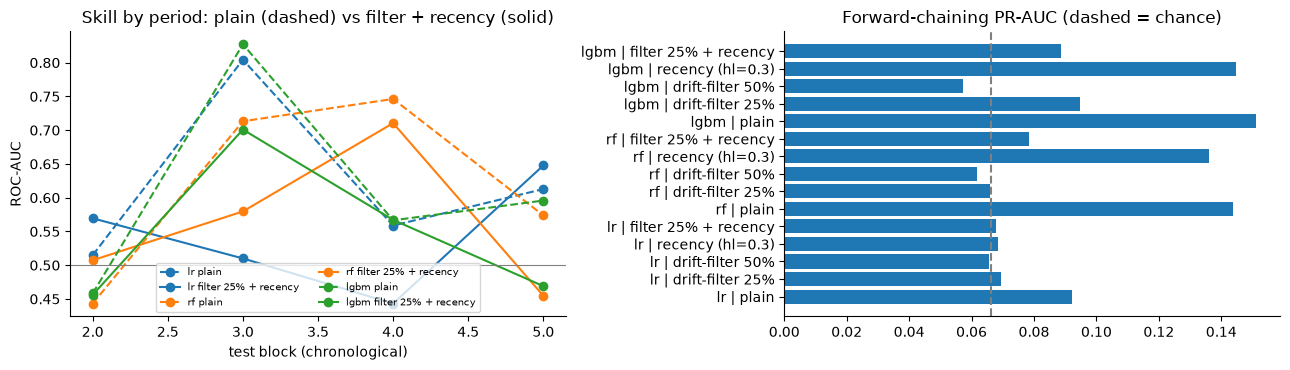

Best single model under forward-chaining: lgbm | plain | plain best: lgbm | plain


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for kind, c in zip(["lr", "rf", "lgbm"], ["C0", "C1", "C2"]):
    for vname, ls in [("plain", "--"), ("filter 25% + recency", "-")]:
        fm = [roc_auc_score(y[b], r) for (a, b), r in zip(FWD, FWD_RISK[f"{kind} | {vname}"])]
        ax[0].plot(range(2, 6), fm, ls, c=c, marker="o", label=f"{kind} {vname}")
ax[0].axhline(0.5, c="grey", lw=.8); ax[0].set_xlabel("test block (chronological)"); ax[0].set_ylabel("ROC-AUC"); ax[0].set_title("Skill by period: plain (dashed) vs filter + recency (solid)"); ax[0].legend(fontsize=7, ncol=2)
best_row = drift_tab["fwd PR-AUC"].idxmax()
ax[1].barh(drift_tab.index, drift_tab["fwd PR-AUC"]); ax[1].axvline(y.mean(), c="grey", ls="--"); ax[1].set_title("Forward-chaining PR-AUC (dashed = chance)")
plt.tight_layout(); plt.show()
print("Best single model under forward-chaining:", best_row, "| plain best:", drift_tab[drift_tab.index.str.endswith('plain')]["fwd PR-AUC"].idxmax())

## 7. Sanity checks

In [18]:
# (a) shuffled labels must give ~chance performance (no leakage in the harness)
rng = np.random.RandomState(1); ysh = rng.permutation(y)
def shuffled_cv():
    out = []
    for tr, te in SPLITS[: N_SPLITS]:
        m = Pipeline(pre_tree() + [("sel", RankSelector(60)), ("m", ET())]).fit(X[tr], ysh[tr])
        r = m.predict_proba(X[te])[:, 1]; out.append((roc_auc_score(ysh[te], r), average_precision_score(ysh[te], r)))
    return np.mean(out, 0)
a, p = shuffled_cv()
print(f"Shuffled labels (selection + ExtraTrees inside folds): ROC-AUC {a:.3f} (expect ≈0.5), PR-AUC {p:.3f} (expect ≈{y.mean():.3f})")

# (b) the harness reproduces the v2 numbers approximately
for n, v2 in [("LR quantile (v2-like)", (0.695, 0.180)), ("RF (v2-like)", (0.742, 0.189))]:
    print(f"{n:24s} here ROC {SCORE[n]['ROC-AUC'].mean():.3f}, PR {SCORE[n]['PR-AUC'].mean():.3f} | v2: ROC {v2[0]:.3f}, PR {v2[1]:.3f}")

Shuffled labels (selection + ExtraTrees inside folds): ROC-AUC 0.460 (expect ≈0.5), PR-AUC 0.091 (expect ≈0.066)
LR quantile (v2-like)    here ROC 0.706, PR 0.179 | v2: ROC 0.695, PR 0.180
RF (v2-like)             here ROC 0.747, PR 0.204 | v2: ROC 0.742, PR 0.189


## 8. Final report

In [19]:
f = ENS[FINAL]
summary = pd.DataFrame({
    "metric": ["PR-AUC", "ROC-AUC", "Recall@top10%", "Cost (inner thr)", "Cost@1/11", "Recall", "Precision", "Flag rate", "MCC"],
    "v3 selected (10 folds)": [f["PR-AUC"].mean(), f["ROC-AUC"].mean(), f["Recall@top10%"].mean(), f["Cost"].mean(), f["cost@1/11"].mean(), f["Recall"].mean(), f["Precision"].mean(), f["Flag rate"].mean(), f["MCC"].mean()],
    "± sd": [f["PR-AUC"].std(), f["ROC-AUC"].std(), f["Recall@top10%"].std(), f["Cost"].std(), f["cost@1/11"].std(), f["Recall"].std(), f["Precision"].std(), f["Flag rate"].std(), f["MCC"].std()],
    "v2 best (avg L1-LR + RF)": [0.224, 0.739, np.nan, 0.490, 0.490, 0.510, 0.171, 0.198, np.nan],
    "majority baseline": [y.mean(), 0.5, 0.10, COST_FN * y.mean(), COST_FN * y.mean(), 0, 0, 0, 0]}).set_index("metric")
summary.round(3).to_csv(RESULTS / f"scoreboard_v3{TAG}.csv"); ens_tab.round(4).to_csv(RESULTS / f"ensembles_v3{TAG}.csv"); time_tab.round(4).to_csv(RESULTS / f"time_split_v3{TAG}.csv")
summary.round(3)

,v3 selected (10 folds),± sd,v2 best (avg L1-LR + RF),majority baseline
metric,,,,
PR-AUC,0.219,0.029,0.224,0.066
ROC-AUC,0.746,0.041,0.739,0.500
Recall@top10%,0.308,0.054,NaN,0.100
Cost (inner thr),0.501,0.052,0.490,0.664
Cost@1/11,0.488,0.083,0.490,0.664
Recall,0.597,0.105,0.510,0.000
Precision,0.151,0.027,0.171,0.000
Flag rate,0.273,0.075,0.198,0.000
MCC,0.198,0.041,NaN,0.000


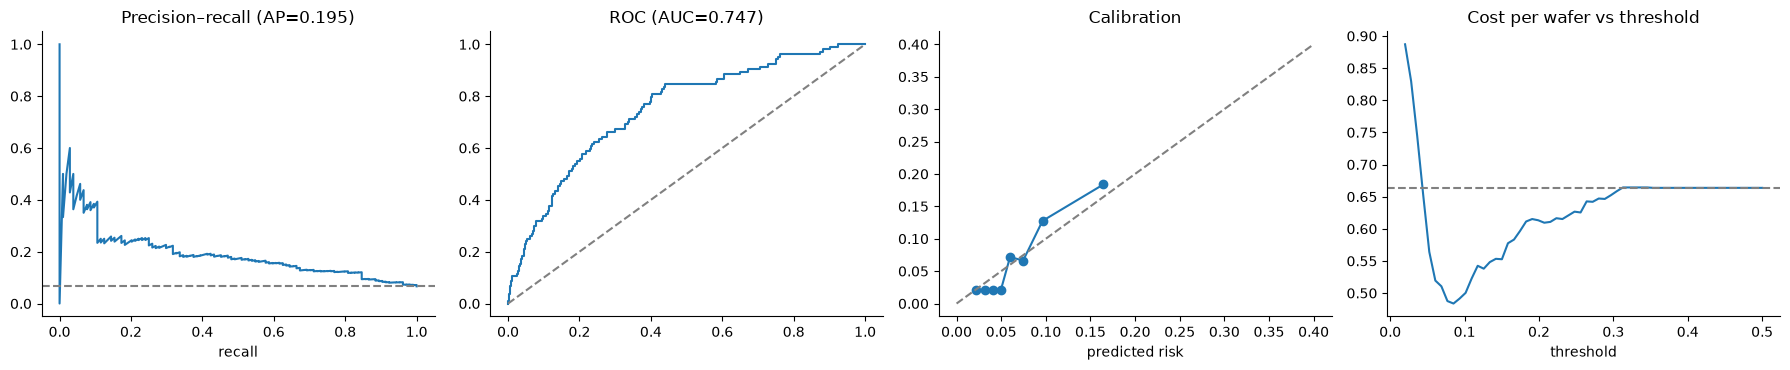

At the median inner-chosen threshold 0.084: Cost=0.483, Recall=0.596, Precision=0.155, Flag rate=0.255, MCC=0.209
flagged     0    1
actual            
0        1126  337
1          42   62


In [20]:
# Curves from pooled outer-test predictions of the selected ensemble (first repeat only: each wafer predicted once)
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.calibration import calibration_curve
rep1 = range(N_SPLITS)
yy = np.concatenate([y[TUNE_SPLITS[i][1]] for i in rep1])
rr = np.concatenate([np.mean([TUNED[i][m]["test"] for m in SETS[FINAL]], 0) for i in rep1])
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
pr, rc, _ = precision_recall_curve(yy, rr); ax[0].plot(rc, pr); ax[0].axhline(y.mean(), ls="--", c="grey"); ax[0].set_title(f"Precision–recall (AP={average_precision_score(yy, rr):.3f})"); ax[0].set_xlabel("recall")
fp_, tp_, _ = roc_curve(yy, rr); ax[1].plot(fp_, tp_); ax[1].plot([0, 1], [0, 1], "--", c="grey"); ax[1].set_title(f"ROC (AUC={roc_auc_score(yy, rr):.3f})")
fr, mp = calibration_curve(yy, rr, n_bins=8, strategy="quantile"); ax[2].plot(mp, fr, "o-"); ax[2].plot([0, .4], [0, .4], "--", c="grey"); ax[2].set_title("Calibration"); ax[2].set_xlabel("predicted risk")
ths = np.linspace(0.02, 0.5, 60); ax[3].plot(ths, [decision_metrics(yy, rr, th)["Cost"] for th in ths]); ax[3].axhline(COST_FN * y.mean(), ls="--", c="grey")
ax[3].set_title("Cost per wafer vs threshold"); ax[3].set_xlabel("threshold")
plt.tight_layout(); plt.show()
thr_med = float(np.median(f["thr"]))
d = decision_metrics(yy, rr, thr_med)
print(f"At the median inner-chosen threshold {thr_med:.3f}: " + ", ".join(f"{k}={v:.3f}" for k, v in d.items()))
cm = pd.crosstab(pd.Series(yy, name="actual"), pd.Series((rr >= thr_med).astype(int), name="flagged")); print(cm)

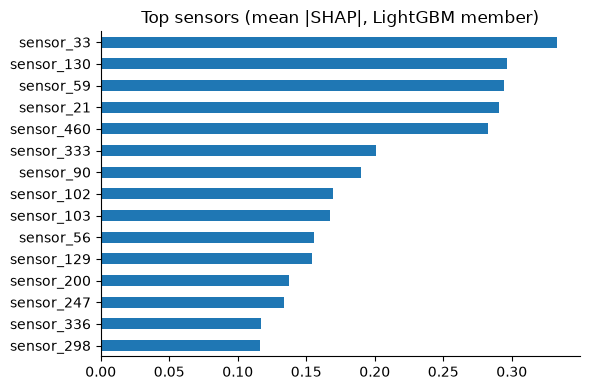

sensor_33     0.3331
sensor_130    0.2968
sensor_59     0.2946
sensor_21     0.2906
sensor_460    0.2828
sensor_333    0.2008
sensor_90     0.1901
sensor_102    0.1697
sensor_103    0.1673
sensor_56     0.1557


In [21]:
# Interpretation: which sensors drive the model? (LightGBM member refitted on all data, SHAP on its own selected sensors — descriptive, not for evaluation)
try:
    import shap
    params = TUNED[int(np.argmax([r_["lgbm"]["inner_pr"] for r_ in TUNED]))]["lgbm"]["params"]
    mdl = make_est("lgbm", params).fit(X, y)
    keep = mdl.named_steps["clean"].keep_[mdl.named_steps["sel"].idx_]
    Xs = mdl[:-1].transform(X)
    sv = shap.TreeExplainer(mdl.named_steps["m"]).shap_values(Xs)
    sv = sv[1] if isinstance(sv, list) else sv
    imp = pd.Series(np.abs(sv).mean(0), index=[f"sensor_{k}" for k in keep]).sort_values(ascending=False)
    imp.head(15).iloc[::-1].plot.barh(figsize=(6, 4), title="Top sensors (mean |SHAP|, LightGBM member)"); plt.tight_layout(); plt.show()
    print(imp.head(10).round(4).to_string())
except Exception as e:
    print("SHAP step skipped:", repr(e))

## 9. Conclusions and limitations

**Result (full run).**
* The selected ensemble (calibrated L1-LR + RF + LightGBM, nested-tuned, 10 outer folds) scores PR-AUC 0.219 ± 0.029, ROC-AUC 0.746, recall 0.60 at precision 0.15, cost 0.50/wafer (0.49 at the fixed 1/11 threshold; majority baseline 0.664).
* This is **statistically indistinguishable from the v2 best** (PR-AUC 0.224, ROC-AUC 0.739, cost 0.490). Against the v2-like LR in the same harness the gain is +0.03 PR-AUC (corrected t ≈ 1.6), i.e. not significant. With 104 failures the practical ceiling of random-CV performance on SECOM appears to be about ROC-AUC 0.75 and PR-AUC 0.22; tuning, boosting, SMOTE, balanced forests and rank-based selection all land inside that noise band.
* The shuffled-label check gives chance-level scores, so the harness is not leaking, and the v2-like baselines reproduce v2's numbers (LR ROC 0.706 vs 0.695; RF 0.747 vs 0.742).

**Drift is the real limitation.**
* On the chronological hold-out (train first 75%, test last 25%, 24 failures) every model is near chance (ROC-AUC 0.51–0.56, PR-AUC ≈ 0.07 = base rate); the selected ensemble does not beat the majority-class cost (0.70 vs 0.61).
* Forward-chaining CV (train on all earlier blocks, test on the next) gives ROC-AUC ≈ 0.65 for the plain rank-averaged ensemble, so there is some forward-looking skill, but much less than random CV suggests.
* Dropping the most-drifting sensors **hurt** in every family (fwd PR-AUC falls from ≈0.16 to ≈0.06–0.09), and recency weighting gave no reliable gain (0.164 vs 0.160 fwd PR-AUC, worse random-CV for LR). The sensors that move most over time are also among the informative ones.
* Random-CV scores should therefore be read as an upper bound; expect much weaker performance on future wafers without periodic retraining.

**Recommendation.** If a single model is needed, use the calibrated LR + RF + LightGBM ensemble with a cost threshold near 0.08, retrained regularly on recent data, and monitor its precision/recall on new lots. Do not expect large gains from further model-family search on this dataset; more fruitful directions are process-aware features (sensor groups per process step), more labelled failures, or drift-adaptive retraining policies evaluated with forward-chaining.

**Caveats.** Picking the best of 15 ensembles on the same 10 folds is mildly optimistic; the hold-out and forward-chaining blocks contain only 11–24 failures each, so they are noisy; the 10:1 cost is an assumption inherited from v2.
